# 01: Cleaning and feature engineering

This notebook **checks** the table that `src/features.py` builds (`video_features`).
It does not create the table, so run `features.bat` first.

Questions:
1. Did the cleaning work? (durations, time zone, missing values)
2. How should we treat **very new videos**?
3. How should we treat **outliers** (viral hits)?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns

# Let the notebook import our own code from src/ (config.py, db.py)
sys.path.insert(0, str(Path.cwd().parent / "src"))
from config import FIGURES_DIR
from db import connect

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

conn = connect()
df = pd.read_sql("SELECT * FROM video_features", conn)
print(f"{len(df)} videos, {df['in_analysis'].sum()} in analysis")

2999 videos, 2758 in analysis


## 1. Did the cleaning work?

In [2]:
# Duration: the raw ISO text next to the seconds we computed
df[["title", "duration_iso", "duration_sec", "length_category"]].sample(5, random_state=1)

,title,duration_iso,duration_sec,length_category
2056,ROG Xbox Ally X FULL REVIEW - Not What I Expec...,PT16M10S,970,long
1742,Why Didn’t They Do This Sooner? - Corsair Gall...,PT14M56S,896,long
2578,The iPhone Duo comes in two colors. Which one ...,PT15S,15,short
2100,MacBook Neo 💚 First Look!,PT54S,54,short
1787,The Weirdest Controller Feature,PT37S,37,short


In [3]:
# Time zone: the same moment in UTC and in Jakarta (7 hours later), plus the parts we extracted
df[["published_at", "published_at_local", "publish_dow", "publish_hour"]].head(3)

,published_at,published_at_local,publish_dow,publish_hour
0,2026-04-07T15:05:15Z,2026-04-07T22:05:15+07:00,Tuesday,22
1,2026-04-07T20:12:19Z,2026-04-08T03:12:19+07:00,Wednesday,3
2,2026-04-08T23:17:32Z,2026-04-09T06:17:32+07:00,Thursday,6


In [4]:
# Missing values: only like ratio should have gaps (UrAvgConsumer hides likes)
df[["view_count", "like_count", "comment_count", "like_view_ratio", "comment_view_ratio"]].isna().sum()

view_count             0
like_count            69
comment_count          0
like_view_ratio       69
comment_view_ratio     0
dtype: int64

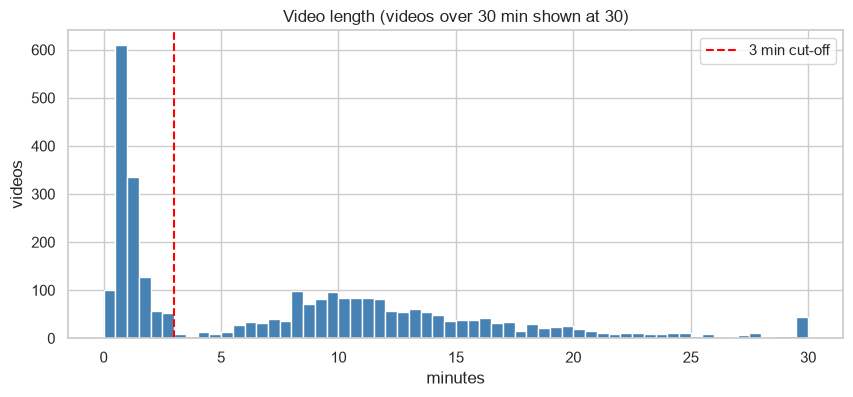

In [5]:
# Why 3 minutes splits shorts from long videos: there is a clear gap in lengths
fig, ax = plt.subplots(figsize=(10, 4))
minutes = df["duration_sec"].clip(upper=1800) / 60
ax.hist(minutes, bins=np.arange(0, 30.5, 0.5), color="steelblue")
ax.axvline(3, color="red", linestyle="--", label="3 min cut-off")
ax.set(title="Video length (videos over 30 min shown at 30)", xlabel="minutes", ylabel="videos")
ax.legend()
plt.show()

## 2. Very new videos

A video earns most of its views in its first days and weeks, then slows down.
So a 3-day-old video's total views are **unfinished**, and its views per day are **inflated** (the early rush, averaged over just a few days).

We test this by comparing each video with its own channel's typical video of the same format:
`views ÷ the channel's median views` (1.0 = normal for that channel). This is an exploratory age check; Step 5 uses the stricter `performance_index`, which also matches age groups.

In [6]:
# All videos except live streams, including the very new ones
v = df[df["was_live"] == 0].copy()
group = ["channel_id", "length_category"]
v["views_vs_typical"] = v["view_count"] / v.groupby(group)["view_count"].transform("median")
v["vpd_vs_typical"] = v["views_per_day"] / v.groupby(group)["views_per_day"].transform("median")

age_bins = [0, 3, 7, 14, 30, 60, 90, 180, 365, np.inf]
age_labels = ["0-3 days", "3-7 days", "1-2 wk", "2-4 wk", "1-2 mo", "2-3 mo", "3-6 mo", "6-12 mo", "1 yr+"]
v["age_bin"] = pd.cut(v["video_age_days"], age_bins, labels=age_labels)

by_age = v.groupby("age_bin", observed=True).agg(
    videos=("video_id", "count"),
    total_views_vs_typical=("views_vs_typical", "median"),
    views_per_day_vs_typical=("vpd_vs_typical", "median"),
).round(2)
by_age

,videos,total_views_vs_typical,views_per_day_vs_typical
age_bin,,,
0-3 days,18,0.44,38.87
3-7 days,49,0.91,24.88
1-2 wk,35,0.98,12.62
2-4 wk,119,1.26,8.56
1-2 mo,292,1.67,5.74
2-3 mo,209,0.87,1.63
3-6 mo,648,0.85,0.91
6-12 mo,841,0.98,0.75
1 yr+,768,1.01,0.65


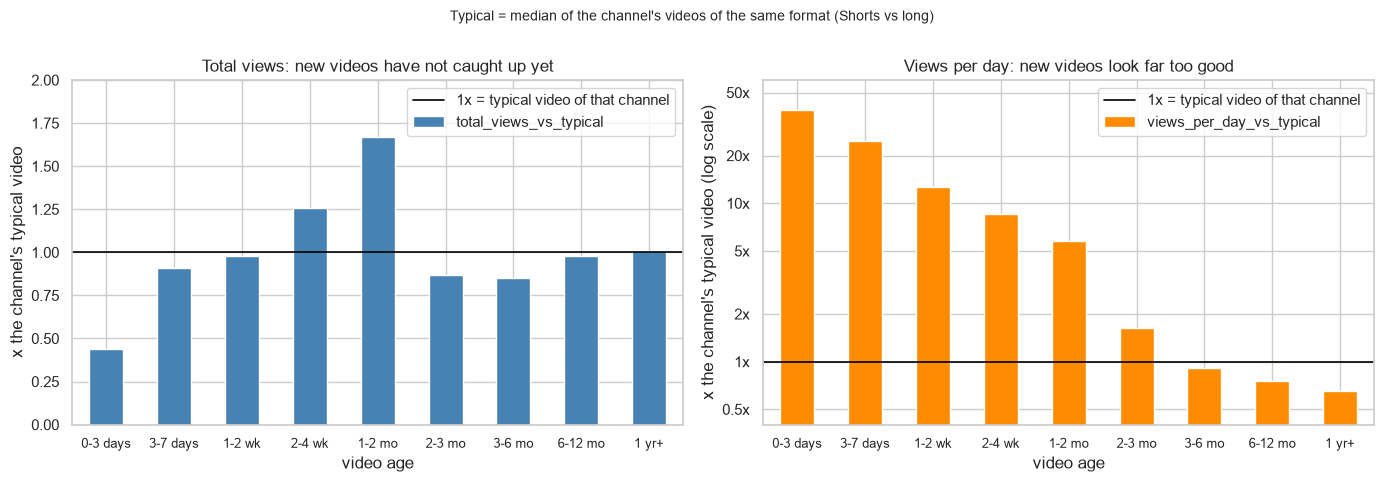

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
by_age["total_views_vs_typical"].plot(kind="bar", ax=axes[0], color="steelblue", ylim=(0, 2))
axes[0].set(title="Total views: new videos have not caught up yet",
            xlabel="video age", ylabel="x the channel's typical video")

by_age["views_per_day_vs_typical"].plot(kind="bar", ax=axes[1], color="darkorange", logy=True)
axes[1].set(title="Views per day: new videos look far too good",
            xlabel="video age", ylabel="x the channel's typical video (log scale)")
axes[1].set_ylim(0.4, 60)
axes[1].set_yticks([0.5, 1, 2, 5, 10, 20, 50])
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}x"))
axes[1].yaxis.set_minor_formatter(FuncFormatter(lambda y, _: ""))

for ax in axes:
    ax.axhline(1, color="black", linewidth=1.2, label="1x = typical video of that channel")
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    ax.legend(loc="upper right")
fig.suptitle("Typical = median of the channel's videos of the same format (Shorts vs long)", y=1.0, fontsize=10)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "04_age_effect.png", dpi=130, bbox_inches="tight")
plt.show()

**What we see**
- **Total views** (left): videos under 3 days old have less than half the views of a typical video. After about 1-2 weeks they reach normal.
- **Views per day** (right): very new videos look up to **30x better** than typical, because the early rush is divided by a tiny number of days. Even videos 1-2 months old are still clearly above 1.

**What we do**
1. **Leave out videos younger than 30 days** (`in_analysis = 0`, reason `too new`). They stay in the table, so we can show them in the dashboard as "still collecting views".
2. **Compare videos of similar age** using `age_group`. Views per day still shrinks slowly after 30 days, so a fair comparison is "30-90-day-old Shorts vs 30-90-day-old long videos", not everything at once.
3. **Pick a cut-off you can defend, not a perfect one.** 30 days is a common rule of thumb. A stricter 60 days would remove another ~290 videos (about 10% of the data).

**Something to keep in mind:** videos 1-2 months old (Sept 2026) are above normal *even in total views*. Part of that is the new iPhone launch: 34% of these titles mention iPhone, compared with 8% of older videos. Launch season is a real effect, not an error, but it means **upload month and topic also relate to views**. That's another reason we only claim correlation.

## 3. Outliers

### Why the average is misleading here

views per day: mean = 9,432, median = 1,519
the top 1% of videos get 28% of all views per day


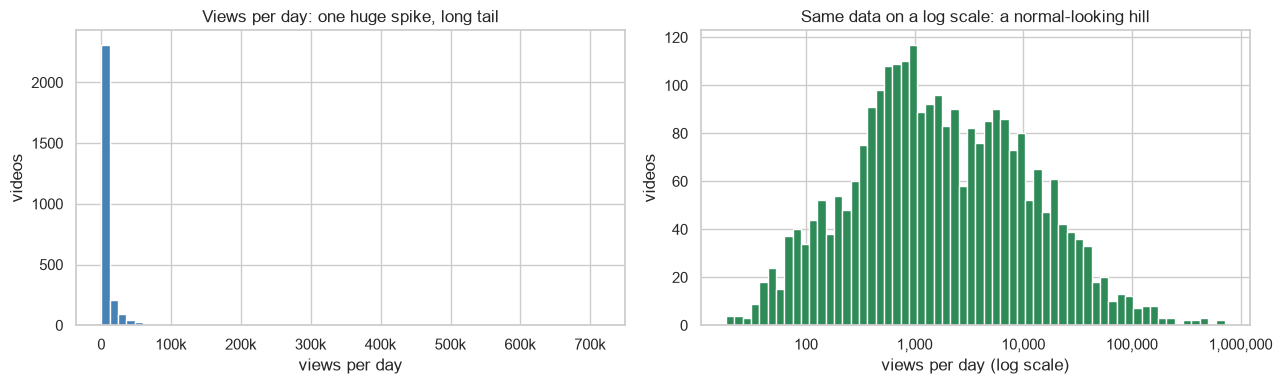

In [8]:
a = df[df["in_analysis"] == 1]
print(f"views per day: mean = {a['views_per_day'].mean():,.0f}, median = {a['views_per_day'].median():,.0f}")
print(f"the top 1% of videos get {a['views_per_day'].nlargest(len(a) // 100).sum() / a['views_per_day'].sum():.0%} of all views per day")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(a["views_per_day"], bins=60, color="steelblue")
axes[0].set(title="Views per day: one huge spike, long tail", xlabel="views per day", ylabel="videos")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:,.0f}k" if x else "0"))
axes[1].hist(np.log10(a["views_per_day"]), bins=60, color="seagreen")
axes[1].set(title="Same data on a log scale: a normal-looking hill",
            xlabel="views per day (log scale)", ylabel="videos")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{10 ** x:,.0f}"))
plt.tight_layout()
fig.savefig(FIGURES_DIR / "04_views_skew.png", dpi=130, bbox_inches="tight")
plt.show()

View counts are **heavily skewed**: most videos get a modest number of views, and a few go viral.
A single 10-million-view video can drag a group's **mean** up by a lot, so it says more about one lucky video than about the group.

### Our approach: don't delete outliers, handle them
| Method | What it does | Where we use it |
|---|---|---|
| **Median** instead of mean | One viral video can't move it much | every "which group is better?" comparison |
| **Log scale** (`log10`) | Puts 100 and 1,000,000 views on one readable chart | charts and correlations |
| **Compare to similar videos** (`performance_index`) | A video's views per day are compared with the same channel, format and age group | finding "breakout" videos in Step 5 |

Outliers are **real videos**, not mistakes. Viral hits are the most interesting part of a performance study, so we keep them and use methods they can't distort.

Delete a row only if it's an **error** (impossible values, duplicates). We found none: likes are never higher than views, and no video appears twice.

In [9]:
# Why compare to the channel's own median: the same view count means very different things
example = (a[a["length_category"] == "long"]
           .groupby("channel_name")["view_count"].median()
           .sort_values())
print("Median views of a long video, by channel:")
print(example.map("{:,.0f}".format).to_string())

Median views of a long video, by channel:
channel_name
iJustine                 61,494
ZONEofTECH              105,610
Hardware Canucks        108,688
Max Tech                114,720
ShortCircuit            195,616
The Tech Chap           232,296
UrAvgConsumer           322,866
SuperSaf                361,608
Austin Evans            509,298
Dave2D                  744,668
JerryRigEverything    1,173,870
Unbox Therapy         1,195,015
Linus Tech Tips       1,252,855
Marques Brownlee      4,760,788
Mrwhosetheboss        5,662,990


In [10]:
# Biggest breakouts: performance compared with similar videos of that channel
cols = ["channel_name", "length_category", "age_group", "view_count", "typical_views_per_day", "performance_index", "title"]
a.nlargest(8, "performance_index")[cols]

,channel_name,length_category,age_group,view_count,typical_views_per_day,performance_index,title
2887,iJustine,short,180-365 days,8170977,161.60,250.324,Check out Slackbot today!
2149,The Tech Chap,short,90-180 days,9450408,526.70,165.967,The Phone with a 3D Hologram!
2808,iJustine,short,180-365 days,7034067,161.60,133.890,My Holiday Tech Recommendations
2512,UrAvgConsumer,short,180-365 days,1421787,65.85,86.475,I tried the Speediance Gym Monster 2 at CES an...
2448,UrAvgConsumer,short,1 year+,1877036,71.50,71.580,This @PredatorGaming Helios Neo 16S AI gaming...
708,JerryRigEverything,short,180-365 days,22148297,2197.20,50.153,LEGO wants me to delete this
1483,Mrwhosetheboss,short,1 year+,281390634,12992.90,48.991,$1000 RC Cars vs Boats
1663,ShortCircuit,short,180-365 days,6966633,715.40,48.977,Guess the price!


**Check before trusting a breakout:** several of the top Shorts are **sponsored** (`Check out Slackbot today!`, `#GooglePartner ...`).
Brand deals often come with paid promotion (ads that push the video), so those views aren't all organic.
The API can't tell us whether a video was promoted. That's a limitation to state in the README, and a reason to read the titles before drawing conclusions from the top 10.

## Summary of cleaning decisions
| Decision | Rows affected | Why |
|---|---|---|
| Drop scheduled (not yet published) videos | 1 | not a real video yet: 0 views, no length |
| Leave out live streams | 20 | 2-4 hour streams behave differently from uploads |
| Leave out videos younger than 30 days | 221 | views are still coming in fast |
| Keep hidden likes as missing (NaN), not 0 | 65 in analysis | 0 would wrongly drag UrAvgConsumer's like ratio down |
| Keep outliers, use medians and log scale | all | viral hits are real data |
| Shorts = 3 minutes or less | 1,191 in analysis | API has no "is Short" flag; clear gap at 3 minutes |

In [11]:
conn.close()